In [ ]:
!apt-get install openjdk-17-jdk-headless -qq > /dev/null


In [ ]:
!pip install pyspark==3.5.6 -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.6 which is incompatible.


In [ ]:
print("Java and PySpark installation completed!")

Java and PySpark installation completed!


In [ ]:
import pyspark
import os

print("PySpark Version:", pyspark.__version__)
print("Java Home:", os.environ.get("JAVA_HOME"))

PySpark Version: 3.5.6
Java Home: None


In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("FlightPricePrediction") \
    .getOrCreate()

print("Spark Version:", spark.version)
print("Spark Session Created Successfully!")

Spark Version: 3.5.6
Spark Session Created Successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Clean_Dataset.csv to Clean_Dataset.csv


In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("FlightPricePrediction") \
    .master("local[*]") \
    .getOrCreate()

print("Spark Session Created Successfully!")
print("Spark Version:", spark.version)

Spark Session Created Successfully!
Spark Version: 4.0.5


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Clean_Dataset.csv to Clean_Dataset.csv


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'Clean_Dataset.csv', 'sample_data']


In [ ]:
file_path = "/content/Clean_Dataset.csv"

df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=True
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'Clean_Dataset.csv', 'sample_data']


In [ ]:
file_path = "/content/Clean_Dataset.csv"

df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=True
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

Total Rows: 300153
Total Columns: 12


In [ ]:
#Display the first 10 rows
df.show(10, truncate=False)

+---+--------+-------+-----------+--------------+-----+-------------+----------------+-------+--------+---------+-----+
|_c0|airline |flight |source_city|departure_time|stops|arrival_time |destination_city|class  |duration|days_left|price|
+---+--------+-------+-----------+--------------+-----+-------------+----------------+-------+--------+---------+-----+
|0  |SpiceJet|SG-8709|Delhi      |Evening       |zero |Night        |Mumbai          |Economy|2.17    |1        |5953 |
|1  |SpiceJet|SG-8157|Delhi      |Early_Morning |zero |Morning      |Mumbai          |Economy|2.33    |1        |5953 |
|2  |AirAsia |I5-764 |Delhi      |Early_Morning |zero |Early_Morning|Mumbai          |Economy|2.17    |1        |5956 |
|3  |Vistara |UK-995 |Delhi      |Morning       |zero |Afternoon    |Mumbai          |Economy|2.25    |1        |5955 |
|4  |Vistara |UK-963 |Delhi      |Morning       |zero |Morning      |Mumbai          |Economy|2.33    |1        |5955 |
|5  |Vistara |UK-945 |Delhi      |Mornin

In [ ]:
#Check column names and data types
df.printSchema()


root
 |-- _c0: integer (nullable = true)
 |-- airline: string (nullable = true)
 |-- flight: string (nullable = true)
 |-- source_city: string (nullable = true)
 |-- departure_time: string (nullable = true)
 |-- stops: string (nullable = true)
 |-- arrival_time: string (nullable = true)
 |-- destination_city: string (nullable = true)
 |-- class: string (nullable = true)
 |-- duration: double (nullable = true)
 |-- days_left: integer (nullable = true)
 |-- price: integer (nullable = true)



In [ ]:
#Get statistical information
df.describe().show()

+-------+-----------------+-------+--------------------+-----------+--------------+------+------------+----------------+--------+------------------+------------------+------------------+
|summary|              _c0|airline|              flight|source_city|departure_time| stops|arrival_time|destination_city|   class|          duration|         days_left|             price|
+-------+-----------------+-------+--------------------+-----------+--------------+------+------------+----------------+--------+------------------+------------------+------------------+
|  count|           300153| 300153|              300153|     300153|        300153|300153|      300153|          300153|  300153|            300153|            300153|            300153|
|   mean|         150076.0|   NULL|5.427411873908629...|       NULL|          NULL|  NULL|        NULL|            NULL|    NULL|12.221020812717926|26.004750910369044|20889.660523133203|
| stddev|86646.85201148395|   NULL|1.803651814074488...|       NU

In [ ]:
#missing values
from pyspark.sql.functions import col, sum

df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
]).show()

+---+-------+------+-----------+--------------+-----+------------+----------------+-----+--------+---------+-----+
|_c0|airline|flight|source_city|departure_time|stops|arrival_time|destination_city|class|duration|days_left|price|
+---+-------+------+-----------+--------------+-----+------------+----------------+-----+--------+---------+-----+
|  0|      0|     0|          0|             0|    0|           0|               0|    0|       0|        0|    0|
+---+-------+------+-----------+--------------+-----+------------+----------------+-----+--------+---------+-----+



In [ ]:
# Check duplicate records

total_rows = df.count()
unique_rows = df.dropDuplicates().count()

duplicates = total_rows - unique_rows

print("Total Rows:", total_rows)
print("Unique Rows:", unique_rows)
print("Duplicate Rows:", duplicates)

Total Rows: 300153
Unique Rows: 300153
Duplicate Rows: 0


In [ ]:
# Check unique values in each column

from pyspark.sql.functions import countDistinct

for column in df.columns:
    print(column, ":", df.select(
        countDistinct(column)
    ).first()[0])

_c0 : 300153
airline : 6
flight : 1561
source_city : 6
departure_time : 6
stops : 3
arrival_time : 6
destination_city : 6
class : 2
duration : 476
days_left : 49
price : 12157


In [ ]:
# Remove unnecessary index and flight identifier
df = df.drop("_c0", "flight")

# Display updated columns
print("Updated Columns:")
print(df.columns)

# Display updated schema
df.printSchema()

Updated Columns:
['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']
root
 |-- airline: string (nullable = true)
 |-- source_city: string (nullable = true)
 |-- departure_time: string (nullable = true)
 |-- stops: string (nullable = true)
 |-- arrival_time: string (nullable = true)
 |-- destination_city: string (nullable = true)
 |-- class: string (nullable = true)
 |-- duration: double (nullable = true)
 |-- days_left: integer (nullable = true)
 |-- price: integer (nullable = true)



In [ ]:
categorical_columns = [
    "airline",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "class"
]

for column in categorical_columns:
    print("\n", column)
    df.groupBy(column).count().orderBy(column).show()


 airline
+---------+------+
|  airline| count|
+---------+------+
|  AirAsia| 16098|
|Air_India| 80892|
| GO_FIRST| 23173|
|   Indigo| 43120|
| SpiceJet|  9011|
|  Vistara|127859|
+---------+------+


 source_city
+-----------+-----+
|source_city|count|
+-----------+-----+
|  Bangalore|52061|
|    Chennai|38700|
|      Delhi|61343|
|  Hyderabad|40806|
|    Kolkata|46347|
|     Mumbai|60896|
+-----------+-----+


 departure_time
+--------------+-----+
|departure_time|count|
+--------------+-----+
|     Afternoon|47794|
| Early_Morning|66790|
|       Evening|65102|
|    Late_Night| 1306|
|       Morning|71146|
|         Night|48015|
+--------------+-----+


 stops
+-----------+------+
|      stops| count|
+-----------+------+
|        one|250863|
|two_or_more| 13286|
|       zero| 36004|
+-----------+------+


 arrival_time
+-------------+-----+
| arrival_time|count|
+-------------+-----+
|    Afternoon|38139|
|Early_Morning|15417|
|      Evening|78323|
|   Late_Night|14001|
|      Morn

In [ ]:
# Summary statistics of numerical columns
numerical_columns = ["duration", "days_left", "price"]

df.select(numerical_columns).describe().show()

+-------+------------------+------------------+------------------+
|summary|          duration|         days_left|             price|
+-------+------------------+------------------+------------------+
|  count|            300153|            300153|            300153|
|   mean|12.221020812717926|26.004750910369044|20889.660523133203|
| stddev| 7.191997238118976| 13.56100368709348|22697.767366074524|
|    min|              0.83|                 1|              1105|
|    max|             49.83|                49|            123071|
+-------+------------------+------------------+------------------+



In [ ]:
# Correlation analysis
correlation = df.select(
    "duration",
    "days_left",
    "price"
).toPandas().corr()

print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
           duration  days_left     price
duration   1.000000  -0.039157  0.204222
days_left -0.039157   1.000000 -0.091949
price      0.204222  -0.091949  1.000000


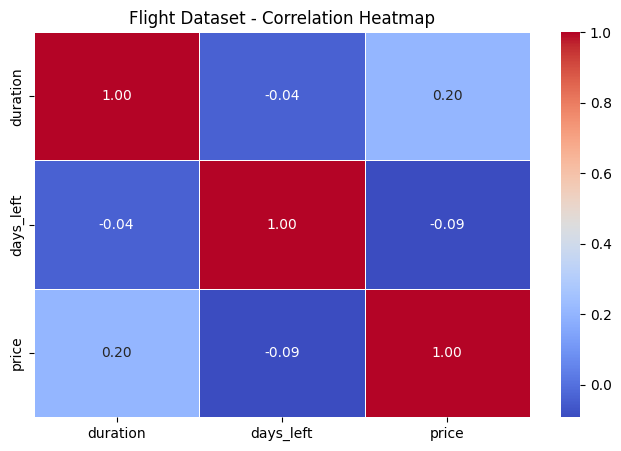

In [ ]:
#correlation heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Flight Dataset - Correlation Heatmap")
plt.show()

In [ ]:
#Data Preprocessing for PySpark ML.
#Import PySpark ML libraries
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler
)

from pyspark.ml.regression import (
    LinearRegression,
    DecisionTreeRegressor
)

from pyspark.ml.clustering import (
    KMeans,
    BisectingKMeans
)

from pyspark.ml.evaluation import (
    RegressionEvaluator,
    ClusteringEvaluator
)

print("All PySpark ML libraries imported successfully!")

All PySpark ML libraries imported successfully!


In [ ]:
#Separate Features and Target Variable.
#In supervised machine learning:
#- Features (X): Input columns used to predict the flight price.
# Target (y): The price column we want to predict.
# Separate input features and target variable

feature_columns = [
    "airline",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "class",
    "duration",
    "days_left"
]

X = df.select(feature_columns)
y = df.select("price")

print("Feature Columns:")
print(X.columns)

print("\nTarget Column:")
print(y.columns)

print("\nFeature Data:")
X.show(5)

print("\nTarget Data:")
y.show(5)

Feature Columns:
['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left']

Target Column:
['price']

Feature Data:
+--------+-----------+--------------+-----+-------------+----------------+-------+--------+---------+
| airline|source_city|departure_time|stops| arrival_time|destination_city|  class|duration|days_left|
+--------+-----------+--------------+-----+-------------+----------------+-------+--------+---------+
|SpiceJet|      Delhi|       Evening| zero|        Night|          Mumbai|Economy|    2.17|        1|
|SpiceJet|      Delhi| Early_Morning| zero|      Morning|          Mumbai|Economy|    2.33|        1|
| AirAsia|      Delhi| Early_Morning| zero|Early_Morning|          Mumbai|Economy|    2.17|        1|
| Vistara|      Delhi|       Morning| zero|    Afternoon|          Mumbai|Economy|    2.25|        1|
| Vistara|      Delhi|       Morning| zero|      Morning|          Mumbai|Economy|    2.33|        1|
+-

In [ ]:
# Categorical features
categorical_columns = [
    "airline",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "class"
]

# Numerical features
numerical_columns = [
    "duration",
    "days_left"
]

print("Categorical Features:", categorical_columns)
print("Number of Categorical Features:", len(categorical_columns))

print("\nNumerical Features:", numerical_columns)
print("Number of Numerical Features:", len(numerical_columns))

Categorical Features: ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']
Number of Categorical Features: 7

Numerical Features: ['duration', 'days_left']
Number of Numerical Features: 2


In [ ]:
#Convert Categorical Features into Numerical Values.
from pyspark.ml.feature import StringIndexer, OneHotEncoder

# Create StringIndexer stages
indexers = [
    StringIndexer(
        inputCol=column,
        outputCol=column + "_index",
        handleInvalid="keep"
    )
    for column in categorical_columns
]

# Create OneHotEncoder stages
encoders = [
    OneHotEncoder(
        inputCol=column + "_index",
        outputCol=column + "_encoded"
    )
    for column in categorical_columns
]

print("StringIndexer and OneHotEncoder stages created successfully!")

StringIndexer and OneHotEncoder stages created successfully!


In [ ]:
#Apply StringIndexer and OneHotEncoder
# Combine indexers and encoders into one pipeline
encoding_pipeline = Pipeline(
    stages=indexers + encoders
)

# Fit the pipeline on the dataset
encoding_model = encoding_pipeline.fit(df)

# Transform the dataset
encoded_df = encoding_model.transform(df)

# Display encoded columns
encoded_columns = [
    column + "_encoded"
    for column in categorical_columns
]

encoded_df.select(
    categorical_columns + encoded_columns
).show(10, truncate=False)

+--------+-----------+--------------+-----+-------------+----------------+-------+---------------+-------------------+----------------------+-------------+--------------------+------------------------+-------------+
|airline |source_city|departure_time|stops|arrival_time |destination_city|class  |airline_encoded|source_city_encoded|departure_time_encoded|stops_encoded|arrival_time_encoded|destination_city_encoded|class_encoded|
+--------+-----------+--------------+-----+-------------+----------------+-------+---------------+-------------------+----------------------+-------------+--------------------+------------------------+-------------+
|SpiceJet|Delhi      |Evening       |zero |Night        |Mumbai          |Economy|(6,[5],[1.0])  |(6,[0],[1.0])      |(6,[2],[1.0])         |(3,[1],[1.0])|(6,[0],[1.0])       |(6,[0],[1.0])           |(2,[0],[1.0])|
|SpiceJet|Delhi      |Early_Morning |zero |Morning      |Mumbai          |Economy|(6,[5],[1.0])  |(6,[0],[1.0])      |(6,[1],[1.0])     

In [ ]:
#Assemble All Features.
from pyspark.ml.feature import VectorAssembler

# Select encoded and numerical features
assembler_inputs = [
    column + "_encoded"
    for column in categorical_columns
] + numerical_columns

# Create VectorAssembler
assembler = VectorAssembler(
    inputCols=assembler_inputs,
    outputCol="features"
)

# Transform dataset
assembled_df = assembler.transform(encoded_df)

# Display assembled features
assembled_df.select(
    "features",
    "price"
).show(5, truncate=False)

print("Feature assembly completed successfully!")

+----------------------------------------------------------------------+-----+
|features                                                              |price|
+----------------------------------------------------------------------+-----+
|(37,[5,6,14,19,21,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.17,1.0])|5953 |
|(37,[5,6,13,19,23,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.33,1.0])|5953 |
|(37,[4,6,13,19,25,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.17,1.0])|5956 |
|(37,[0,6,12,19,24,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.25,1.0])|5955 |
|(37,[0,6,12,19,23,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.33,1.0])|5955 |
+----------------------------------------------------------------------+-----+
only showing top 5 rows
Feature assembly completed successfully!


In [ ]:
# Prepare regression dataset
regression_df = assembled_df.select(
    "features",
    "price"
)

# Remove rows with missing values
regression_df = regression_df.dropna(
    subset=["features", "price"]
)

print("Regression Dataset:")
regression_df.show(5, truncate=False)

print("Total Regression Records:", regression_df.count())

Regression Dataset:
+----------------------------------------------------------------------+-----+
|features                                                              |price|
+----------------------------------------------------------------------+-----+
|(37,[5,6,14,19,21,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.17,1.0])|5953 |
|(37,[5,6,13,19,23,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.33,1.0])|5953 |
|(37,[4,6,13,19,25,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.17,1.0])|5956 |
|(37,[0,6,12,19,24,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.25,1.0])|5955 |
|(37,[0,6,12,19,23,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.33,1.0])|5955 |
+----------------------------------------------------------------------+-----+
only showing top 5 rows
Total Regression Records: 300153


In [ ]:
# Split dataset into training and testing
train_df, test_df = regression_df.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training Records:", train_df.count())
print("Testing Records:", test_df.count())

print("Total Records:", train_df.count() + test_df.count())


Training Records: 240168
Testing Records: 59985
Total Records: 300153


In [ ]:
# Prepare clustering features without price
clustering_df = assembled_df.select(
    "features"
)

# Remove missing feature records
clustering_df = clustering_df.dropna(
    subset=["features"]
)

print("Clustering Dataset:")
clustering_df.show(5, truncate=False)

print("Total Clustering Records:", clustering_df.count())

Clustering Dataset:
+----------------------------------------------------------------------+
|features                                                              |
+----------------------------------------------------------------------+
|(37,[5,6,14,19,21,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.17,1.0])|
|(37,[5,6,13,19,23,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.33,1.0])|
|(37,[4,6,13,19,25,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.17,1.0])|
|(37,[0,6,12,19,24,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.25,1.0])|
|(37,[0,6,12,19,23,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.33,1.0])|
+----------------------------------------------------------------------+
only showing top 5 rows
Total Clustering Records: 300153


In [ ]:
#Standardize Clustering Features
from pyspark.ml.feature import StandardScaler

# Create StandardScaler
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withStd=True,
    withMean=False
)

# Fit scaler
scaler_model = scaler.fit(clustering_df)

# Transform clustering dataset
scaled_clustering_df = scaler_model.transform(clustering_df)

# Display standardized features
scaled_clustering_df.select(
    "scaled_features"
).show(5, truncate=False)

print("Feature Scaling Completed!")

+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|scaled_features                                                                                                                                                                                           |
+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|(37,[5,6,14,19,21,27,33,35,36],[5.86007318180733,2.479894497341564,2.426407546470864,3.077812102388343,2.1720433524274627,2.5147816033772052,2.159393731535411,0.3017242537995677,0.07374085451740846])   |
|(37,[5,6,13,19,23,27,33,35,36],[5.86007318180733,2.479894497341564,2.4041980670203764,3.077812102388343,2.4594057990718605,2.5147816033772052,2.159393731535411,0.32397120338847596

In [ ]:
#Supervised Machine Learning.
#Linear Regression
#Decision Tree Regression
from pyspark.ml.regression import LinearRegression

# Create Linear Regression model
lr = LinearRegression(
    featuresCol="features",
    labelCol="price",
    maxIter=100,
    regParam=0.1
)

# Train the model
lr_model = lr.fit(train_df)

print("Linear Regression Model Trained Successfully!")





Linear Regression Model Trained Successfully!


In [ ]:
# Generate predictions
lr_predictions = lr_model.transform(test_df)

# Display actual and predicted prices
lr_predictions.select(
    "price",
    "prediction"
).show(10, truncate=False)

print("Linear Regression Predictions Generated Successfully!")

+-----+------------------+
|price|prediction        |
+-----+------------------+
|18713|12351.68608082072 |
|12150|11826.370463559244|
|12150|11301.054846297768|
|6296 |10644.410324720924|
|6296 |9856.43689882871  |
|6296 |9331.121281567233 |
|6296 |8411.818951359652 |
|6296 |7492.51662115207  |
|12150|12110.570490907605|
|12150|11979.241586592234|
+-----+------------------+
only showing top 10 rows
Linear Regression Predictions Generated Successfully!


In [ ]:
#Evaluate Linear Regression
# Create evaluation metrics
evaluator_rmse = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="rmse"
)

evaluator_mae = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="mae"
)

evaluator_r2 = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="r2"
)

# Calculate metrics
lr_rmse = evaluator_rmse.evaluate(lr_predictions)
lr_mae = evaluator_mae.evaluate(lr_predictions)
lr_r2 = evaluator_r2.evaluate(lr_predictions)


print("RMSE:", lr_rmse)
print("MAE:", lr_mae)
print("R2 Score:", lr_r2)

RMSE: 6730.945560596376
MAE: 4558.208881803961
R2 Score: 0.9115479184988258


In [ ]:
#Decision Tree Regression
from pyspark.ml.regression import DecisionTreeRegressor

# Create Decision Tree model
dt = DecisionTreeRegressor(
    featuresCol="features",
    labelCol="price",
    maxDepth=10,
    minInstancesPerNode=5
)

# Train the model
dt_model = dt.fit(train_df)

print("Decision Tree Regression Model Trained Successfully!")

Decision Tree Regression Model Trained Successfully!


In [ ]:
# Generate predictions using Decision Tree
dt_predictions = dt_model.transform(test_df)

# Display actual and predicted prices
dt_predictions.select(
    "price",
    "prediction"
).show(10, truncate=False)

print("Decision Tree Predictions Generated Successfully!")

+-----+------------------+
|price|prediction        |
+-----+------------------+
|18713|13728.834498834498|
|12150|11633.482935153583|
|12150|11633.482935153583|
|6296 |6237.842281879195 |
|6296 |5603.038728107146 |
|6296 |5603.038728107146 |
|6296 |5603.038728107146 |
|6296 |5603.038728107146 |
|12150|11633.482935153583|
|12150|11633.482935153583|
+-----+------------------+
only showing top 10 rows
Decision Tree Predictions Generated Successfully!


In [ ]:
# Calculate Decision Tree evaluation metrics

dt_rmse = evaluator_rmse.evaluate(dt_predictions)
dt_mae = evaluator_mae.evaluate(dt_predictions)
dt_r2 = evaluator_r2.evaluate(dt_predictions)


print("RMSE:", dt_rmse)
print("MAE:", dt_mae)
print("R2 Score:", dt_r2)

RMSE: 4436.507873992417
MAE: 2464.4618959897443
R2 Score: 0.9615728288514048


In [ ]:
#Compare Regression Models
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "RMSE": [lr_rmse, dt_rmse],
    "MAE": [lr_mae, dt_mae],
    "R2 Score": [lr_r2, dt_r2]
})

print("REGRESSION MODEL COMPARISON")
display(comparison)

REGRESSION MODEL COMPARISON


,Model,RMSE,MAE,R2 Score
0,Linear Regression,6730.945561,4558.208882,0.911548
1,Decision Tree,4436.507874,2464.461896,0.961573


In [ ]:
#Train the K-Means Model
#we initially create 3 clusters
from pyspark.ml.clustering import KMeans

kmeans = KMeans(
    featuresCol="scaled_features",
    predictionCol="cluster",
    k=3,
    seed=42,
    maxIter=100
)

kmeans_model = kmeans.fit(scaled_clustering_df)

print("K-Means Model Trained Successfully!")

K-Means Model Trained Successfully!


In [ ]:
kmeans_predictions = kmeans_model.transform(scaled_clustering_df)

kmeans_predictions.select(
    "scaled_features",
    "cluster"
).show(10, truncate=False)

print("K-Means Predictions Generated Successfully!")

+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|scaled_features                                                                                                                                                                                           |cluster|
+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|(37,[5,6,14,19,21,27,33,35,36],[5.86007318180733,2.479894497341564,2.426407546470864,3.077812102388343,2.1720433524274627,2.5147816033772052,2.159393731535411,0.3017242537995677,0.07374085451740846])   |1      |
|(37,[5,6,13,19,23,27,33,35,36],[5.86007318180733,2.479894497341564,2.4041980670203764,3.077812102388343,2.4594057990718605,2.5147816033772052,2.159

In [ ]:
#Evaluate K-Means using Silhouette Score
from pyspark.ml.evaluation import ClusteringEvaluator

clustering_evaluator = ClusteringEvaluator(
    featuresCol="scaled_features",
    predictionCol="cluster",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

kmeans_silhouette = clustering_evaluator.evaluate(kmeans_predictions)

print("K-MEANS CLUSTERING RESULTS")
print("Silhouette Score:", kmeans_silhouette)

K-MEANS CLUSTERING RESULTS
Silhouette Score: 0.09299365913747439


In [ ]:
#Analyze Cluster Distribution
print("K-MEANS CLUSTER DISTRIBUTION")

kmeans_predictions.groupBy("cluster") \
    .count() \
    .orderBy("cluster") \
    .show()

K-MEANS CLUSTER DISTRIBUTION
+-------+------+
|cluster| count|
+-------+------+
|      0| 43918|
|      1|130511|
|      2|125724|
+-------+------+



In [ ]:
# Cluster Distribution Analysis
print("K-MEANS CLUSTER DISTRIBUTION")

kmeans_predictions.groupBy("cluster") \
    .count() \
    .orderBy("cluster") \
    .show()

K-MEANS CLUSTER DISTRIBUTION
+-------+------+
|cluster| count|
+-------+------+
|      0| 43918|
|      1|130511|
|      2|125724|
+-------+------+



In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("FlightPricePrediction") \
    .master("local[*]") \
    .getOrCreate()

print("Spark Session Restored Successfully!")
print("Spark Version:", spark.version)

Spark Session Restored Successfully!
Spark Version: 4.0.5


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

project_path = "/content/drive/MyDrive/FlightProject"

os.makedirs(project_path, exist_ok=True)

print("Project folder created successfully!")
print(project_path)

Project folder created successfully!
/content/drive/MyDrive/FlightProject


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Clean_Dataset.csv to Clean_Dataset.csv


In [ ]:
import shutil
import os

source_file = "/content/Clean_Dataset.csv"
destination_file = "/content/drive/MyDrive/FlightProject/Clean_Dataset.csv"

shutil.copy(source_file, destination_file)

print("Dataset saved successfully in Google Drive!")
print(destination_file)

Dataset saved successfully in Google Drive!
/content/drive/MyDrive/FlightProject/Clean_Dataset.csv


In [ ]:
df = spark.read.csv(
    "/content/drive/MyDrive/FlightProject/Clean_Dataset.csv",
    header=True,
    inferSchema=True
)

print("Dataset loaded successfully!")
print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

df.show(5)

Dataset loaded successfully!
Total Rows: 300153
Total Columns: 12
+---+--------+-------+-----------+--------------+-----+-------------+----------------+-------+--------+---------+-----+
|_c0| airline| flight|source_city|departure_time|stops| arrival_time|destination_city|  class|duration|days_left|price|
+---+--------+-------+-----------+--------------+-----+-------------+----------------+-------+--------+---------+-----+
|  0|SpiceJet|SG-8709|      Delhi|       Evening| zero|        Night|          Mumbai|Economy|    2.17|        1| 5953|
|  1|SpiceJet|SG-8157|      Delhi| Early_Morning| zero|      Morning|          Mumbai|Economy|    2.33|        1| 5953|
|  2| AirAsia| I5-764|      Delhi| Early_Morning| zero|Early_Morning|          Mumbai|Economy|    2.17|        1| 5956|
|  3| Vistara| UK-995|      Delhi|       Morning| zero|    Afternoon|          Mumbai|Economy|    2.25|        1| 5955|
|  4| Vistara| UK-963|      Delhi|       Morning| zero|      Morning|          Mumbai|Economy|

In [ ]:
#Encode categorical columns
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler

# Remove unnecessary columns
df = df.drop("_c0", "flight")

# Categorical columns
categorical_cols = [
    "airline",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "class"
]

# Convert categorical values into numerical indexes
indexers = [
    StringIndexer(
        inputCol=col,
        outputCol=col + "_index",
        handleInvalid="keep"
    )
    for col in categorical_cols
]

# One-hot encoding
encoder = OneHotEncoder(
    inputCols=[col + "_index" for col in categorical_cols],
    outputCols=[col + "_encoded" for col in categorical_cols]
)

# Combine all features
assembler = VectorAssembler(
    inputCols=[col + "_encoded" for col in categorical_cols]
              + ["duration", "days_left"],
    outputCol="features"
)

# Build and fit pipeline
encoding_pipeline = Pipeline(stages=indexers + [encoder, assembler])
encoding_model = encoding_pipeline.fit(df)

# Transform dataset
assembled_df = encoding_model.transform(df)

print("Categorical encoding completed!")
assembled_df.select("features", "price").show(5, truncate=False)

Categorical encoding completed!
+----------------------------------------------------------------------+-----+
|features                                                              |price|
+----------------------------------------------------------------------+-----+
|(37,[5,6,14,19,21,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.17,1.0])|5953 |
|(37,[5,6,13,19,23,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.33,1.0])|5953 |
|(37,[4,6,13,19,25,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.17,1.0])|5956 |
|(37,[0,6,12,19,24,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.25,1.0])|5955 |
|(37,[0,6,12,19,23,27,33,35,36],[1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.33,1.0])|5955 |
+----------------------------------------------------------------------+-----+
only showing top 5 rows


In [ ]:
## Prepare data for supervised learning

regression_df = assembled_df.select("features", "price").dropna()

# Split dataset into training and testing data
train_df, test_df = regression_df.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Regression data prepared successfully!")
print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

Regression data prepared successfully!
Training rows: 240168
Testing rows: 59985


In [ ]:
#Prepare clustering data
# Prepare features for clustering
clustering_df = assembled_df.select("features").dropna()

print("Clustering data prepared!")
print("Total rows:", clustering_df.count())

Clustering data prepared!
Total rows: 300153


In [ ]:
#Apply StandardScaler
from pyspark.ml.feature import StandardScaler

scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withStd=True,
    withMean=False
)

scaler_model = scaler.fit(clustering_df)

scaled_clustering_df = scaler_model.transform(clustering_df)

print("Feature scaling completed successfully!")

scaled_clustering_df.select("scaled_features").show(5, truncate=False)

Feature scaling completed successfully!
+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|scaled_features                                                                                                                                                                                           |
+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|(37,[5,6,14,19,21,27,33,35,36],[5.86007318180733,2.479894497341564,2.426407546470864,3.077812102388343,2.1720433524274627,2.5147816033772052,2.159393731535411,0.3017242537995677,0.07374085451740846])   |
|(37,[5,6,13,19,23,27,33,35,36],[5.86007318180733,2.479894497341564,2.4041980670203764,3.077812102388343,2.4594057990718605,2.51478160337720

In [ ]:
#Save preprocessing models
encoding_model.write().overwrite().save(
    "/content/drive/MyDrive/FlightProject/encoding_model"
)

scaler_model.write().overwrite().save(
    "/content/drive/MyDrive/FlightProject/scaler_model"
)

print("Encoding model saved successfully!")
print("Scaler model saved successfully!")

Encoding model saved successfully!
Scaler model saved successfully!


In [ ]:
#Train Linear Regression and Decision Tree
from pyspark.ml.regression import LinearRegression, DecisionTreeRegressor

# Linear Regression
lr = LinearRegression(
    featuresCol="features",
    labelCol="price"
)
lr_model = lr.fit(train_df)

# Decision Tree Regression
dt = DecisionTreeRegressor(
    featuresCol="features",
    labelCol="price",
    maxDepth=10
)
dt_model = dt.fit(train_df)

print("Linear Regression trained successfully!")
print("Decision Tree trained successfully!")

Linear Regression trained successfully!
Decision Tree trained successfully!


In [ ]:
#Save Regression Models
lr_model.write().overwrite().save(
    "/content/drive/MyDrive/FlightProject/linear_regression_model"
)

dt_model.write().overwrite().save(
    "/content/drive/MyDrive/FlightProject/decision_tree_model"
)

print("Linear Regression model saved!")
print("Decision Tree model saved!")

Linear Regression model saved!
Decision Tree model saved!


In [ ]:
#Model Evaluation
from pyspark.ml.evaluation import RegressionEvaluator

# Generate predictions
lr_predictions = lr_model.transform(test_df)
dt_predictions = dt_model.transform(test_df)

# Evaluation metrics
evaluator_rmse = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="rmse"
)

evaluator_mae = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="mae"
)

evaluator_r2 = RegressionEvaluator(
    labelCol="price",
    predictionCol="prediction",
    metricName="r2"
)

# Linear Regression results
lr_rmse = evaluator_rmse.evaluate(lr_predictions)
lr_mae = evaluator_mae.evaluate(lr_predictions)
lr_r2 = evaluator_r2.evaluate(lr_predictions)

# Decision Tree results
dt_rmse = evaluator_rmse.evaluate(dt_predictions)
dt_mae = evaluator_mae.evaluate(dt_predictions)
dt_r2 = evaluator_r2.evaluate(dt_predictions)

print("LINEAR REGRESSION")
print("RMSE:", lr_rmse)
print("MAE:", lr_mae)
print("R2:", lr_r2)

print("\nDECISION TREE")
print("RMSE:", dt_rmse)
print("MAE:", dt_mae)
print("R2:", dt_r2)

LINEAR REGRESSION
RMSE: 6730.945872100804
MAE: 4558.209416312113
R2: 0.9115479103117989

DECISION TREE
RMSE: 4392.917593329739
MAE: 2456.4925170383653
R2: 0.9623242406525648


In [ ]:
#Regression Model Comparison
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "RMSE": [lr_rmse, dt_rmse],
    "MAE": [lr_mae, dt_mae],
    "R2 Score": [lr_r2, dt_r2]
})

print("REGRESSION MODEL COMPARISON")
display(comparison)

REGRESSION MODEL COMPARISON


,Model,RMSE,MAE,R2 Score
0,Linear Regression,6730.945872,4558.209416,0.911548
1,Decision Tree,4392.917593,2456.492517,0.962324


In [ ]:
#unsupervised model: K-Means Clustering.
from pyspark.ml.clustering import KMeans

kmeans = KMeans(
    featuresCol="scaled_features",
    predictionCol="cluster",
    k=3,
    seed=42,
    maxIter=100
)

kmeans_model = kmeans.fit(scaled_clustering_df)

print("K-Means model trained successfully!")

K-Means model trained successfully!


In [ ]:
#Save K-Means Model
kmeans_model.write().overwrite().save(
    "/content/drive/MyDrive/FlightProject/kmeans_model"
)

print("K-Means model saved successfully!")

K-Means model saved successfully!


In [ ]:
#K-Means Evaluation
from pyspark.ml.evaluation import ClusteringEvaluator

# Generate cluster predictions
kmeans_predictions = kmeans_model.transform(scaled_clustering_df)

# Evaluate clustering performance
clustering_evaluator = ClusteringEvaluator(
    featuresCol="scaled_features",
    predictionCol="cluster",
    metricName="silhouette"
)

kmeans_silhouette = clustering_evaluator.evaluate(kmeans_predictions)

print("K-Means Silhouette Score:", kmeans_silhouette)

K-Means Silhouette Score: 0.09299365913747439


In [ ]:
#Cluster Distribution
kmeans_predictions.groupBy("cluster") \
    .count() \
    .orderBy("cluster") \
    .show()

+-------+------+
|cluster| count|
+-------+------+
|      0| 43918|
|      1|130511|
|      2|125724|
+-------+------+



In [ ]:
#Train Bisecting K-Means
from pyspark.ml.clustering import BisectingKMeans

bkm = BisectingKMeans(
    featuresCol="scaled_features",
    predictionCol="bkm_cluster",
    k=3,
    seed=42,
    maxIter=100
)

bkm_model = bkm.fit(scaled_clustering_df)

print("Bisecting K-Means model trained successfully!")

Bisecting K-Means model trained successfully!


In [ ]:
#Save Bisecting K-Means Model
bkm_model.write().overwrite().save(
    "/content/drive/MyDrive/FlightProject/bisecting_kmeans_model"
)

print("Bisecting K-Means model saved successfully!")

Bisecting K-Means model saved successfully!


In [ ]:
#Bisecting K-Means Evaluation
# Generate predictions
bkm_predictions = bkm_model.transform(scaled_clustering_df)

# Evaluate using Silhouette Score
bkm_evaluator = ClusteringEvaluator(
    featuresCol="scaled_features",
    predictionCol="bkm_cluster",
    metricName="silhouette"
)

bkm_silhouette = bkm_evaluator.evaluate(bkm_predictions)

print("Bisecting K-Means Silhouette Score:", bkm_silhouette)

Bisecting K-Means Silhouette Score: 0.0489470768782148


In [ ]:
#Clustering Model Comparison
import pandas as pd

clustering_comparison = pd.DataFrame({
    "Model": ["K-Means", "Bisecting K-Means"],
    "Silhouette Score": [
        kmeans_silhouette,
        bkm_silhouette
    ]
})

print("CLUSTERING MODEL COMPARISON")
display(clustering_comparison)

CLUSTERING MODEL COMPARISON


,Model,Silhouette Score
0,K-Means,0.092994
1,Bisecting K-Means,0.048947


In [ ]:
#Save Evaluation Results
import pandas as pd
import os

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "K-Means",
        "Bisecting K-Means"
    ],
    "RMSE": [
        lr_rmse,
        dt_rmse,
        None,
        None
    ],
    "MAE": [
        lr_mae,
        dt_mae,
        None,
        None
    ],
    "R2 Score": [
        lr_r2,
        dt_r2,
        None,
        None
    ],
    "Silhouette Score": [
        None,
        None,
        kmeans_silhouette,
        bkm_silhouette
    ]
})

results.to_csv(
    "/content/drive/MyDrive/FlightProject/model_evaluation_results.csv",
    index=False
)

print("All evaluation results saved successfully!")
display(results)

All evaluation results saved successfully!


,Model,RMSE,MAE,R2 Score,Silhouette Score
0,Linear Regression,6730.945872,4558.209416,0.911548,NaN
1,Decision Tree,4392.917593,2456.492517,0.962324,NaN
2,K-Means,NaN,NaN,NaN,0.092994
3,Bisecting K-Means,NaN,NaN,NaN,0.048947


In [ ]:
#Verify saved files
import os

project_path = "/content/drive/MyDrive/FlightProject"

print("SAVED PROJECT FILES\n")

for item in sorted(os.listdir(project_path)):
    full_path = os.path.join(project_path, item)

    if os.path.isdir(full_path):
        print("📁", item)
    else:
        size_mb = os.path.getsize(full_path) / (1024 * 1024)
        print(f"📄 {item} - {size_mb:.2f} MB")

SAVED PROJECT FILES

📄 Clean_Dataset.csv - 23.54 MB
📁 bisecting_kmeans_model
📁 decision_tree_model
📁 encoding_model
📁 kmeans_model
📁 linear_regression_model
📄 model_evaluation_results.csv - 0.00 MB
📁 scaler_model


In [ ]:
from pyspark.ml.regression import (
    LinearRegressionModel,
    DecisionTreeRegressionModel
)

from pyspark.ml.clustering import (
    KMeansModel,
    BisectingKMeansModel
)

# Load saved models
lr_loaded = LinearRegressionModel.load(
    "/content/drive/MyDrive/FlightProject/linear_regression_model"
)

dt_loaded = DecisionTreeRegressionModel.load(
    "/content/drive/MyDrive/FlightProject/decision_tree_model"
)

kmeans_loaded = KMeansModel.load(
    "/content/drive/MyDrive/FlightProject/kmeans_model"
)

bkm_loaded = BisectingKMeansModel.load(
    "/content/drive/MyDrive/FlightProject/bisecting_kmeans_model"
)

print("All four trained models loaded successfully!")

All four trained models loaded successfully!


In [ ]:
# Test Linear Regression
lr_test_predictions = lr_loaded.transform(test_df)

# Test Decision Tree
dt_test_predictions = dt_loaded.transform(test_df)

# Test K-Means
kmeans_test_predictions = kmeans_loaded.transform(
    scaled_clustering_df
)

# Test Bisecting K-Means
bkm_test_predictions = bkm_loaded.transform(
    scaled_clustering_df
)

print("LINEAR REGRESSION PREDICTIONS")
lr_test_predictions.select("price", "prediction").show(5)

print("DECISION TREE PREDICTIONS")
dt_test_predictions.select("price", "prediction").show(5)

print("K-MEANS CLUSTERS")
kmeans_test_predictions.select("cluster").show(5)

print("BISECTING K-MEANS CLUSTERS")
bkm_test_predictions.select("bkm_cluster").show(5)

LINEAR REGRESSION PREDICTIONS
+-----+------------------+
|price|        prediction|
+-----+------------------+
|18713|12351.644755383753|
|12150|11826.326857341119|
|12150| 11301.00895929848|
| 6296|10644.361586745184|
| 6296|  9856.38473968123|
+-----+------------------+
only showing top 5 rows
DECISION TREE PREDICTIONS
+-----+------------------+
|price|        prediction|
+-----+------------------+
|18713|14720.068366164542|
|12150|11429.169892473119|
|12150|11349.744352409638|
| 6296| 6693.864619377163|
| 6296| 5603.989357213184|
+-----+------------------+
only showing top 5 rows
K-MEANS CLUSTERS
+-------+
|cluster|
+-------+
|      1|
|      1|
|      1|
|      1|
|      1|
+-------+
only showing top 5 rows
BISECTING K-MEANS CLUSTERS
+-----------+
|bkm_cluster|
+-----------+
|          2|
|          2|
|          2|
|          2|
|          2|
+-----------+
only showing top 5 rows


In [ ]:
#Create visualization folder
import os

graph_path = "/content/drive/MyDrive/FlightProject/Graphs"

os.makedirs(graph_path, exist_ok=True)

print("Visualization folder created successfully!")

Visualization folder created successfully!


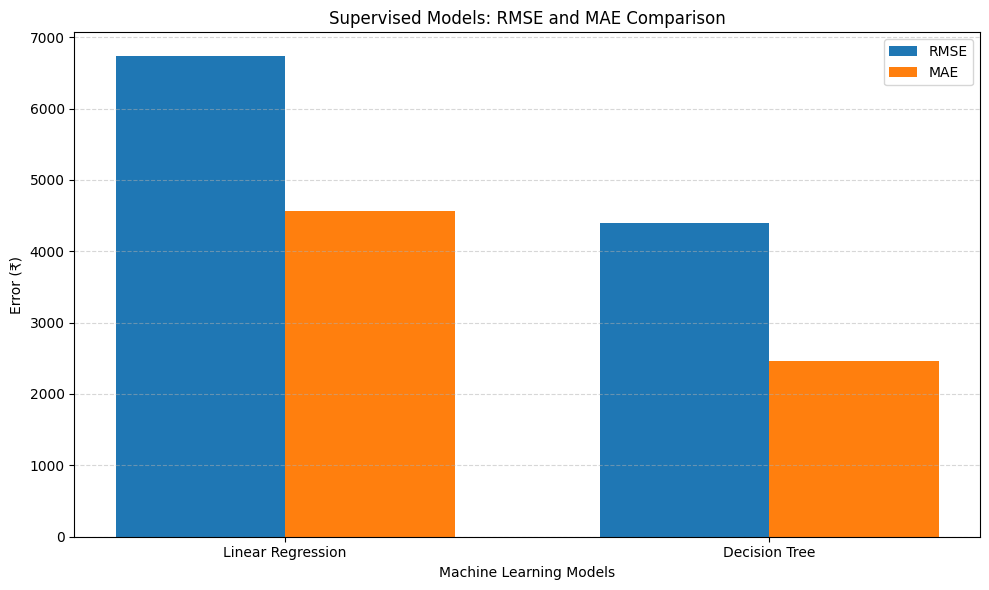

Graph saved successfully in Google Drive!


In [ ]:
#Supervised Learning: RMSE and MAE Comparison
import matplotlib.pyplot as plt
import numpy as np

models = ["Linear Regression", "Decision Tree"]

rmse_values = [lr_rmse, dt_rmse]
mae_values = [lr_mae, dt_mae]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, rmse_values, width, label="RMSE")
plt.bar(x + width/2, mae_values, width, label="MAE")

plt.xlabel("Machine Learning Models")
plt.ylabel("Error (₹)")
plt.title("Supervised Models: RMSE and MAE Comparison")
plt.xticks(x, models)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    graph_path + "/supervised_RMSE_MAE_comparison.png",
    dpi=300
)

plt.show()

print("Graph saved successfully in Google Drive!")

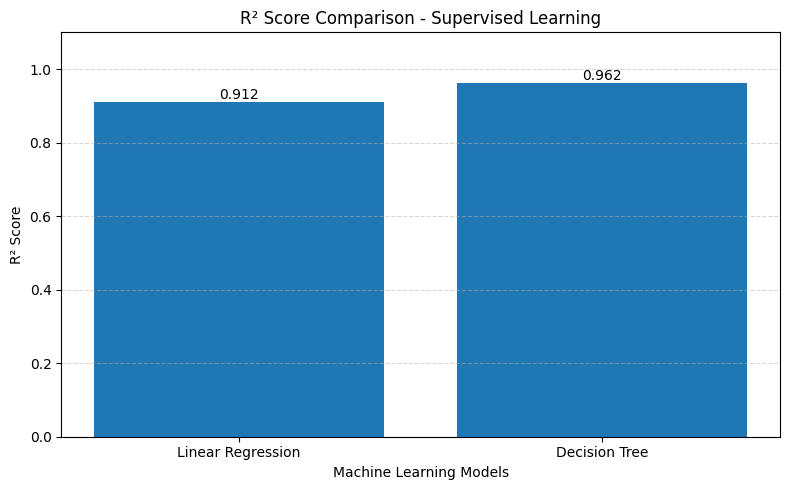

R² comparison graph saved!


In [ ]:
#R² Score Comparison
import matplotlib.pyplot as plt

models = ["Linear Regression", "Decision Tree"]
r2_values = [lr_r2, dt_r2]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, r2_values)

plt.ylabel("R² Score")
plt.xlabel("Machine Learning Models")
plt.title("R² Score Comparison - Supervised Learning")
plt.ylim(0, 1.1)

for bar, value in zip(bars, r2_values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    graph_path + "/supervised_R2_comparison.png",
    dpi=300
)

plt.show()

print("R² comparison graph saved!")

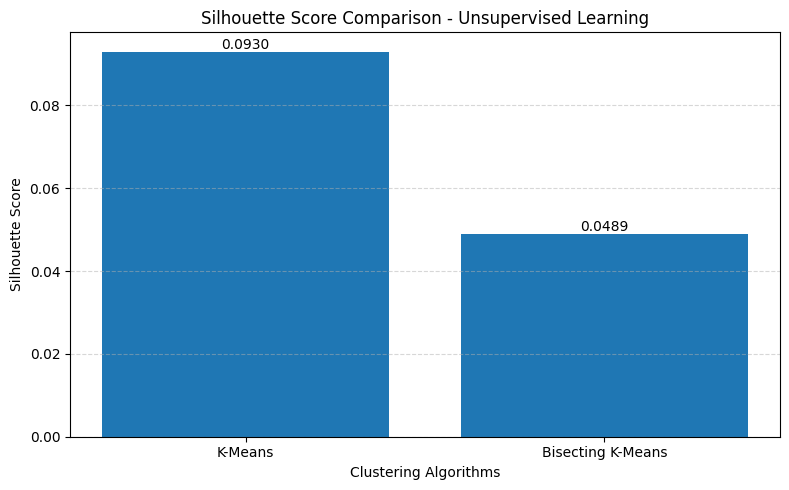

Silhouette comparison graph saved!


In [ ]:
#Silhouette Score Comparison
import matplotlib.pyplot as plt

models = ["K-Means", "Bisecting K-Means"]
scores = [kmeans_silhouette, bkm_silhouette]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, scores)

plt.xlabel("Clustering Algorithms")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison - Unsupervised Learning")

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{score:.4f}",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    graph_path + "/unsupervised_silhouette_comparison.png",
    dpi=300
)

plt.show()

print("Silhouette comparison graph saved!")

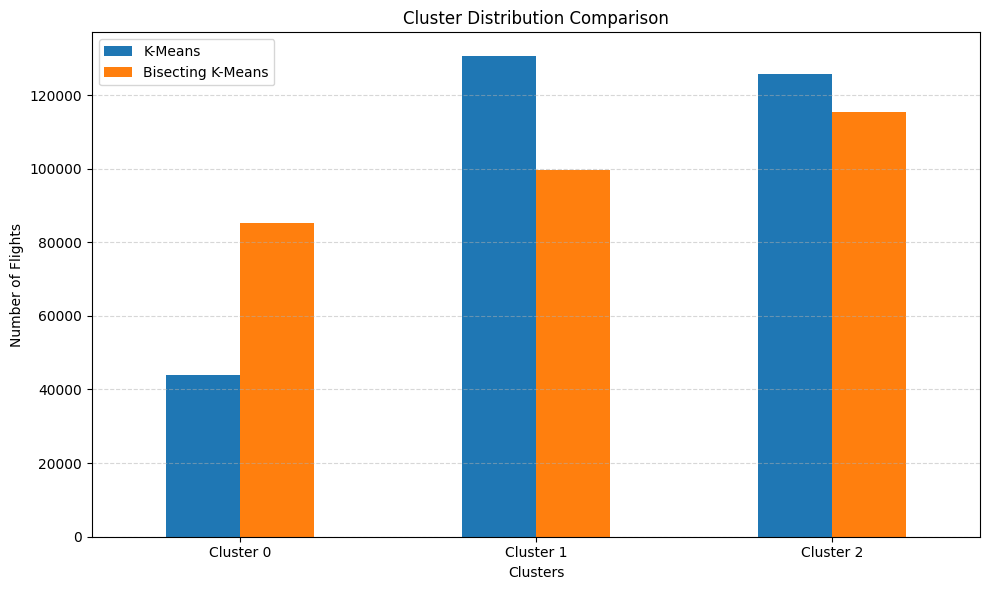

Cluster distribution graph saved!


In [ ]:
#Cluster Distribution Comparison
import matplotlib.pyplot as plt
import pandas as pd

# Get K-Means cluster counts
kmeans_counts = (
    kmeans_predictions.groupBy("cluster")
    .count()
    .orderBy("cluster")
    .toPandas()
)

# Get Bisecting K-Means cluster counts
bkm_counts = (
    bkm_predictions.groupBy("bkm_cluster")
    .count()
    .orderBy("bkm_cluster")
    .toPandas()
)

# Prepare comparison
comparison = pd.DataFrame({
    "K-Means": kmeans_counts["count"].values,
    "Bisecting K-Means": bkm_counts["count"].values
}, index=["Cluster 0", "Cluster 1", "Cluster 2"])

# Plot
comparison.plot(kind="bar", figsize=(10, 6))

plt.title("Cluster Distribution Comparison")
plt.xlabel("Clusters")
plt.ylabel("Number of Flights")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    graph_path + "/cluster_distribution_comparison.png",
    dpi=300
)

plt.show()

print("Cluster distribution graph saved!")

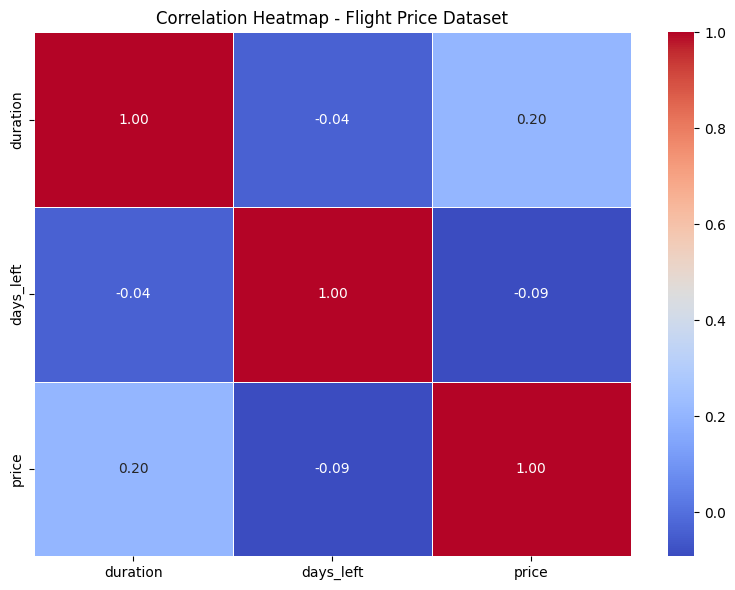

Correlation heatmap saved successfully!


In [ ]:
#Correlation Heatmap
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_df = df.select(
    "duration",
    "days_left",
    "price"
).toPandas()

# Calculate correlation
correlation = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Flight Price Dataset")
plt.tight_layout()

plt.savefig(
    graph_path + "/correlation_heatmap.png",
    dpi=300
)

plt.show()

print("Correlation heatmap saved successfully!")

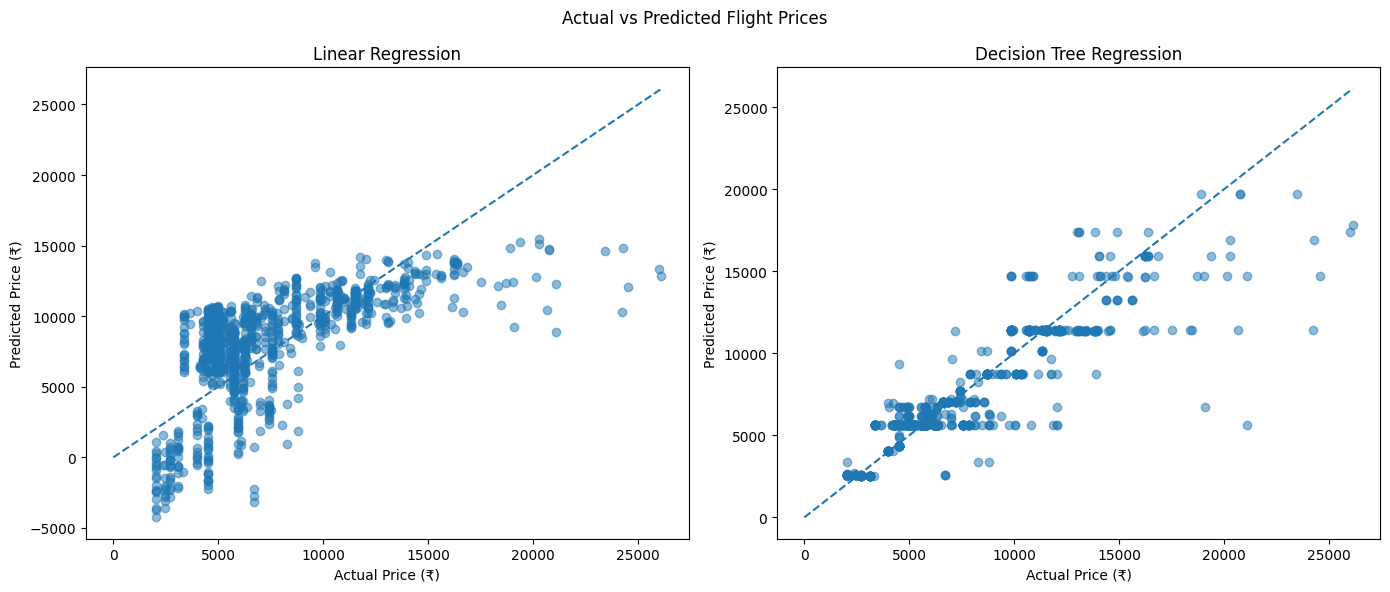

Actual vs Predicted graph saved!


In [ ]:
#Actual vs Predicted Flight Prices
import matplotlib.pyplot as plt

# Take a sample of 1000 test records
lr_sample = lr_predictions.select(
    "price", "prediction"
).limit(1000).toPandas()

dt_sample = dt_predictions.select(
    "price", "prediction"
).limit(1000).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Linear Regression
axes[0].scatter(
    lr_sample["price"],
    lr_sample["prediction"],
    alpha=0.5
)
axes[0].plot(
    [0, lr_sample["price"].max()],
    [0, lr_sample["price"].max()],
    linestyle="--"
)
axes[0].set_title("Linear Regression")
axes[0].set_xlabel("Actual Price (₹)")
axes[0].set_ylabel("Predicted Price (₹)")

# Decision Tree
axes[1].scatter(
    dt_sample["price"],
    dt_sample["prediction"],
    alpha=0.5
)
axes[1].plot(
    [0, dt_sample["price"].max()],
    [0, dt_sample["price"].max()],
    linestyle="--"
)
axes[1].set_title("Decision Tree Regression")
axes[1].set_xlabel("Actual Price (₹)")
axes[1].set_ylabel("Predicted Price (₹)")

plt.suptitle("Actual vs Predicted Flight Prices")
plt.tight_layout()

plt.savefig(
    graph_path + "/actual_vs_predicted.png",
    dpi=300
)

plt.show()

print("Actual vs Predicted graph saved!")

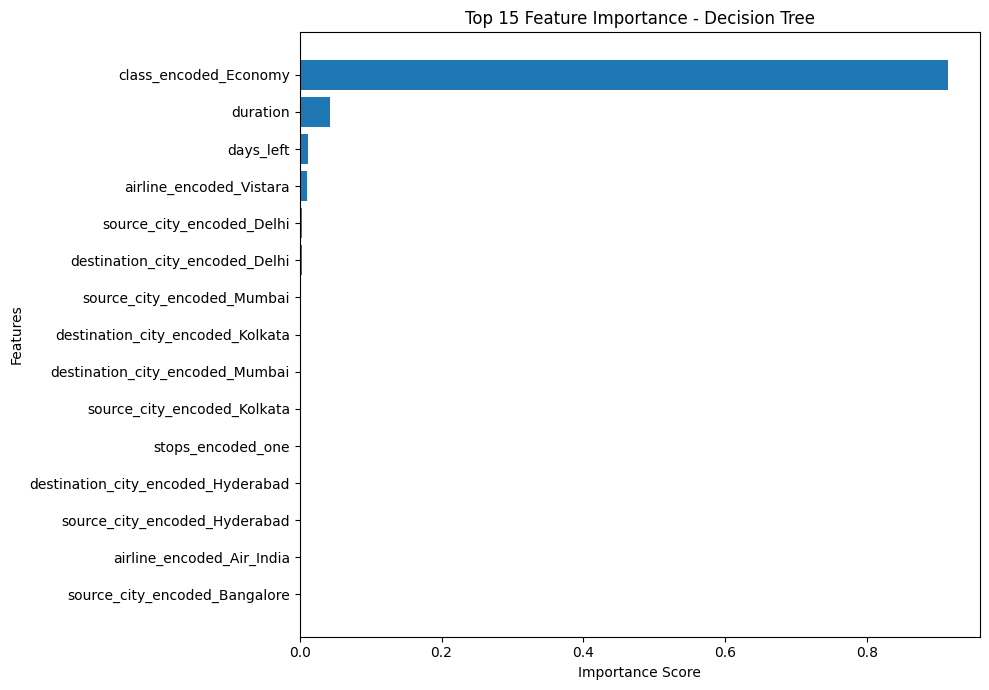

Feature importance graph saved successfully!


In [ ]:
#Feature Importance Graph
import matplotlib.pyplot as plt
import pandas as pd

# Get feature importance values
importance_values = dt_model.featureImportances.toArray()

# Get feature names from Spark metadata
attributes = assembled_df.schema["features"].metadata["ml_attr"]["attrs"]

feature_names = {}

for attribute_type in attributes:
    for attribute in attributes[attribute_type]:
        feature_names[attribute["idx"]] = attribute["name"]

names = [
    feature_names.get(i, f"Feature_{i}")
    for i in range(len(importance_values))
]

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": names,
    "Importance": importance_values
})

# Select top 15 features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

# Plot
plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Feature Importance - Decision Tree")
plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    graph_path + "/decision_tree_feature_importance.png",
    dpi=300
)

plt.show()

print("Feature importance graph saved successfully!")

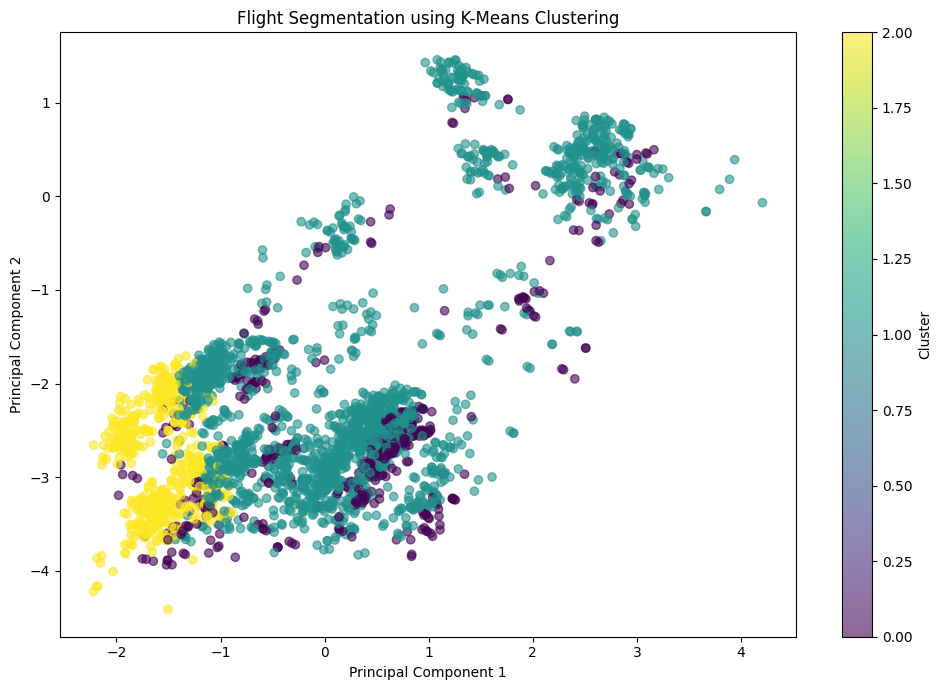

K-Means cluster visualization saved!


In [ ]:
#Visualize Flight Clusters using PCA
import matplotlib.pyplot as plt
from pyspark.ml.feature import PCA
from pyspark.ml.functions import vector_to_array

# Reduce features to 2 dimensions
pca = PCA(
    k=2,
    inputCol="scaled_features",
    outputCol="pca_features"
)

pca_model = pca.fit(scaled_clustering_df)

# Transform K-Means predictions
pca_result = pca_model.transform(kmeans_predictions)

# Take a sample for visualization
plot_df = (
    pca_result
    .select("cluster", "pca_features")
    .sample(False, 0.02, seed=42)
    .limit(3000)
    .withColumn("coords", vector_to_array("pca_features"))
    .selectExpr(
        "cluster",
        "coords[0] as PC1",
        "coords[1] as PC2"
    )
    .toPandas()
)

# Plot clusters
plt.figure(figsize=(10, 7))

plt.scatter(
    plot_df["PC1"],
    plot_df["PC2"],
    c=plot_df["cluster"],
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Flight Segmentation using K-Means Clustering")
plt.colorbar(label="Cluster")
plt.tight_layout()

plt.savefig(
    graph_path + "/kmeans_cluster_visualization.png",
    dpi=300
)

plt.show()

print("K-Means cluster visualization saved!")

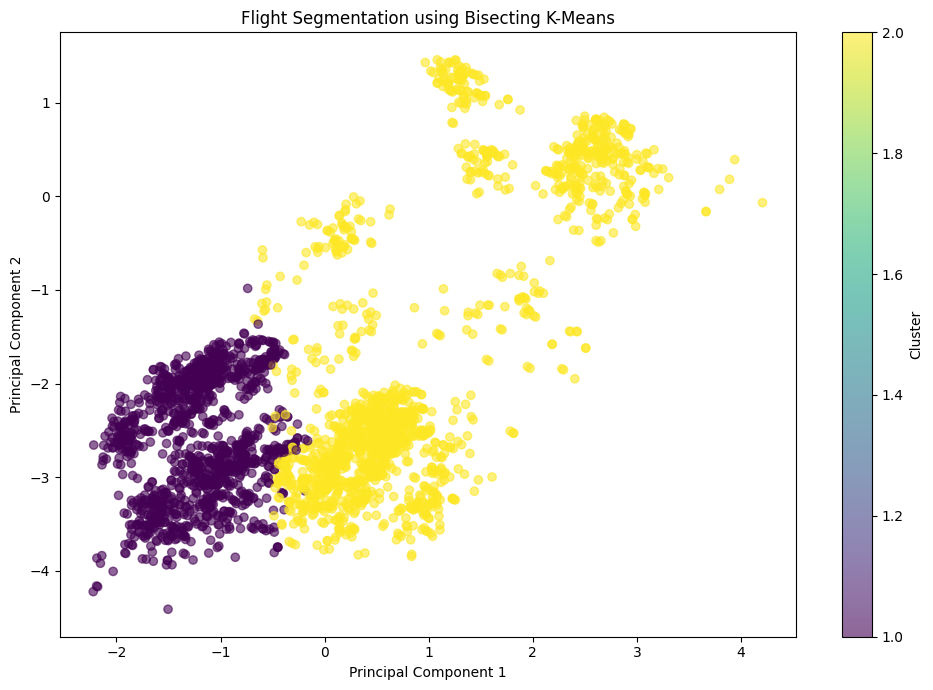

Bisecting K-Means visualization saved!


In [ ]:
#Bisecting K-Means Cluster Visualization
import matplotlib.pyplot as plt
from pyspark.ml.feature import PCA
from pyspark.ml.functions import vector_to_array

# Apply PCA to Bisecting K-Means predictions
bkm_pca = PCA(
    k=2,
    inputCol="scaled_features",
    outputCol="pca_features"
)

bkm_pca_model = bkm_pca.fit(scaled_clustering_df)

bkm_pca_result = bkm_pca_model.transform(bkm_predictions)

# Sample data for visualization
bkm_plot_df = (
    bkm_pca_result
    .select("bkm_cluster", "pca_features")
    .sample(False, 0.02, seed=42)
    .limit(3000)
    .withColumn("coords", vector_to_array("pca_features"))
    .selectExpr(
        "bkm_cluster",
        "coords[0] as PC1",
        "coords[1] as PC2"
    )
    .toPandas()
)

# Plot
plt.figure(figsize=(10, 7))

plt.scatter(
    bkm_plot_df["PC1"],
    bkm_plot_df["PC2"],
    c=bkm_plot_df["bkm_cluster"],
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Flight Segmentation using Bisecting K-Means")
plt.colorbar(label="Cluster")
plt.tight_layout()

plt.savefig(
    graph_path + "/bisecting_kmeans_visualization.png",
    dpi=300
)

plt.show()

print("Bisecting K-Means visualization saved!")

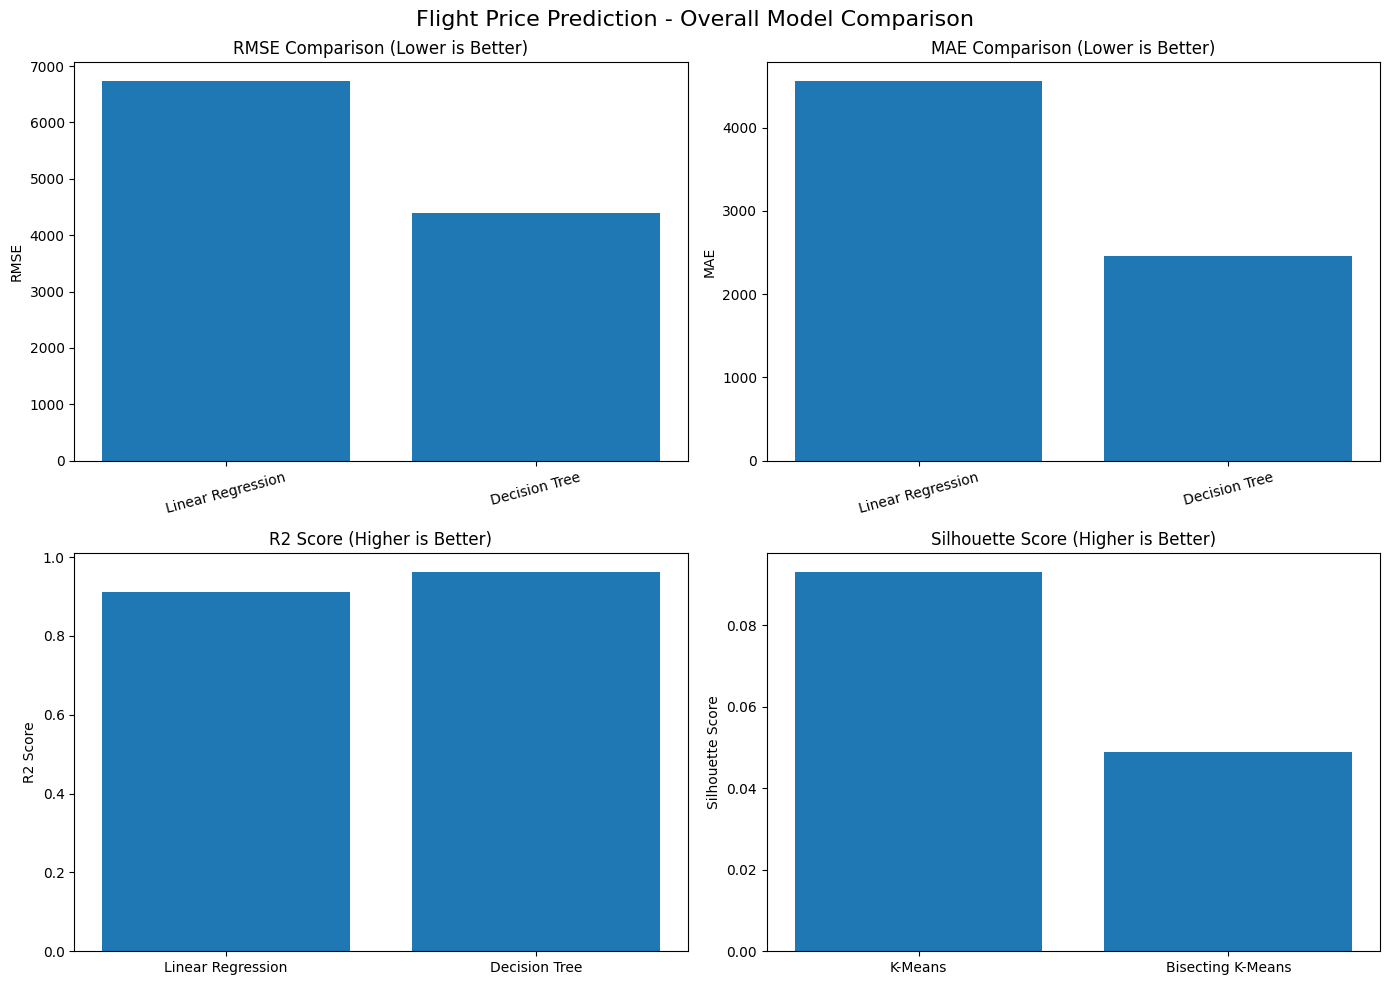

Overall comparison dashboard saved successfully!


In [ ]:
#Overall Model Comparison Dashboard.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. RMSE Comparison
axes[0, 0].bar(
    ["Linear Regression", "Decision Tree"],
    [lr_rmse, dt_rmse]
)
axes[0, 0].set_title("RMSE Comparison (Lower is Better)")
axes[0, 0].set_ylabel("RMSE")
axes[0, 0].tick_params(axis="x", rotation=15)

# 2. MAE Comparison
axes[0, 1].bar(
    ["Linear Regression", "Decision Tree"],
    [lr_mae, dt_mae]
)
axes[0, 1].set_title("MAE Comparison (Lower is Better)")
axes[0, 1].set_ylabel("MAE")
axes[0, 1].tick_params(axis="x", rotation=15)

# 3. R2 Comparison
axes[1, 0].bar(
    ["Linear Regression", "Decision Tree"],
    [lr_r2, dt_r2]
)
axes[1, 0].set_title("R2 Score (Higher is Better)")
axes[1, 0].set_ylabel("R2 Score")

# 4. Silhouette Comparison
axes[1, 1].bar(
    ["K-Means", "Bisecting K-Means"],
    [kmeans_silhouette, bkm_silhouette]
)
axes[1, 1].set_title("Silhouette Score (Higher is Better)")
axes[1, 1].set_ylabel("Silhouette Score")

fig.suptitle(
    "Flight Price Prediction - Overall Model Comparison",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    graph_path + "/overall_model_comparison_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Overall comparison dashboard saved successfully!")

In [ ]:
#Verify all visualization files
import os

graph_path = "/content/drive/MyDrive/FlightProject/Graphs"

print("FLIGHT PROJECT - SAVED GRAPHS")

graph_files = os.listdir(graph_path)

for i, file in enumerate(sorted(graph_files), 1):
    print(f"{i}. {file}")

print("Total graphs saved:", len(graph_files))

FLIGHT PROJECT - SAVED GRAPHS
1. actual_vs_predicted.png
2. bisecting_kmeans_visualization.png
3. cluster_distribution_comparison.png
4. correlation_heatmap.png
5. decision_tree_feature_importance.png
6. kmeans_cluster_visualization.png
7. overall_model_comparison_dashboard.png
8. supervised_R2_comparison.png
9. supervised_RMSE_MAE_comparison.png
10. unsupervised_silhouette_comparison.png
Total graphs saved: 10
